* Please note Section 1 and 2 are same for the prefernece and popularity based model files with only differnece that we took a larger subset of 3000000

* But for SVD we decided to use the entire dataset for Computation

# Section - 1 (Importing The data)

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("saurav9786/amazon-product-reviews")

In [2]:
#import the reqired libraries
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error


from sklearn.model_selection import train_test_split as sklearn_train_test_split
from sklearn.neighbors import NearestNeighbors
import joblib 
import scipy.sparse
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds
import warnings; warnings.simplefilter('ignore')

#Importing Surprise and relevant packages to do some hyper parameter tuning through Grid Search
from surprise import Dataset, Reader, SVD, SVDpp, accuracy
from surprise.model_selection import train_test_split as surprise_train_test_split
from surprise.model_selection import cross_validate
from surprise.model_selection import GridSearchCV
from surprise import KNNBasic, KNNWithMeans, KNNWithZScore
from surprise import SlopeOne, CoClustering
# %matplotlib inline

In [3]:
path = path+"\\ratings_Electronics (1).csv"
columns = ['userId', 'productId', 'rating', 'timestamp']
dataset = pd.read_csv(path, names=columns, header=0)
dataset.head()

,userId,productId,rating,timestamp
0,A2CX7LUOHB2NDG,0321732944,5.0,1341100800
1,A2NWSAGRHCP8N5,0439886341,1.0,1367193600
2,A2WNBOD3WNDNKT,0439886341,3.0,1374451200
3,A1GI0U4ZRJA8WN,0439886341,1.0,1334707200
4,A1QGNMC6O1VW39,0511189877,5.0,1397433600


In [4]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 7824481 entries, 0 to 7824480
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     str    
 1   productId  str    
 2   rating     float64
 3   timestamp  int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 415.9 MB


In [5]:
print('Number of missing values across columns: \n',dataset.isnull().sum())


Number of missing values across columns: 
 userId       0
productId    0
rating       0
timestamp    0
dtype: int64


In [6]:
#Checking the number of rows and columns
rows,columns=dataset.shape
print('Number of rows: ',rows)
print('Number of columns: ',columns)

Number of rows:  7824481
Number of columns:  4


##### So There are no missing records in the dataset

# Section-2 (Analyzing the Data)

array([[<Axes: title={'center': 'rating'}>,
        <Axes: title={'center': 'timestamp'}>]], dtype=object)

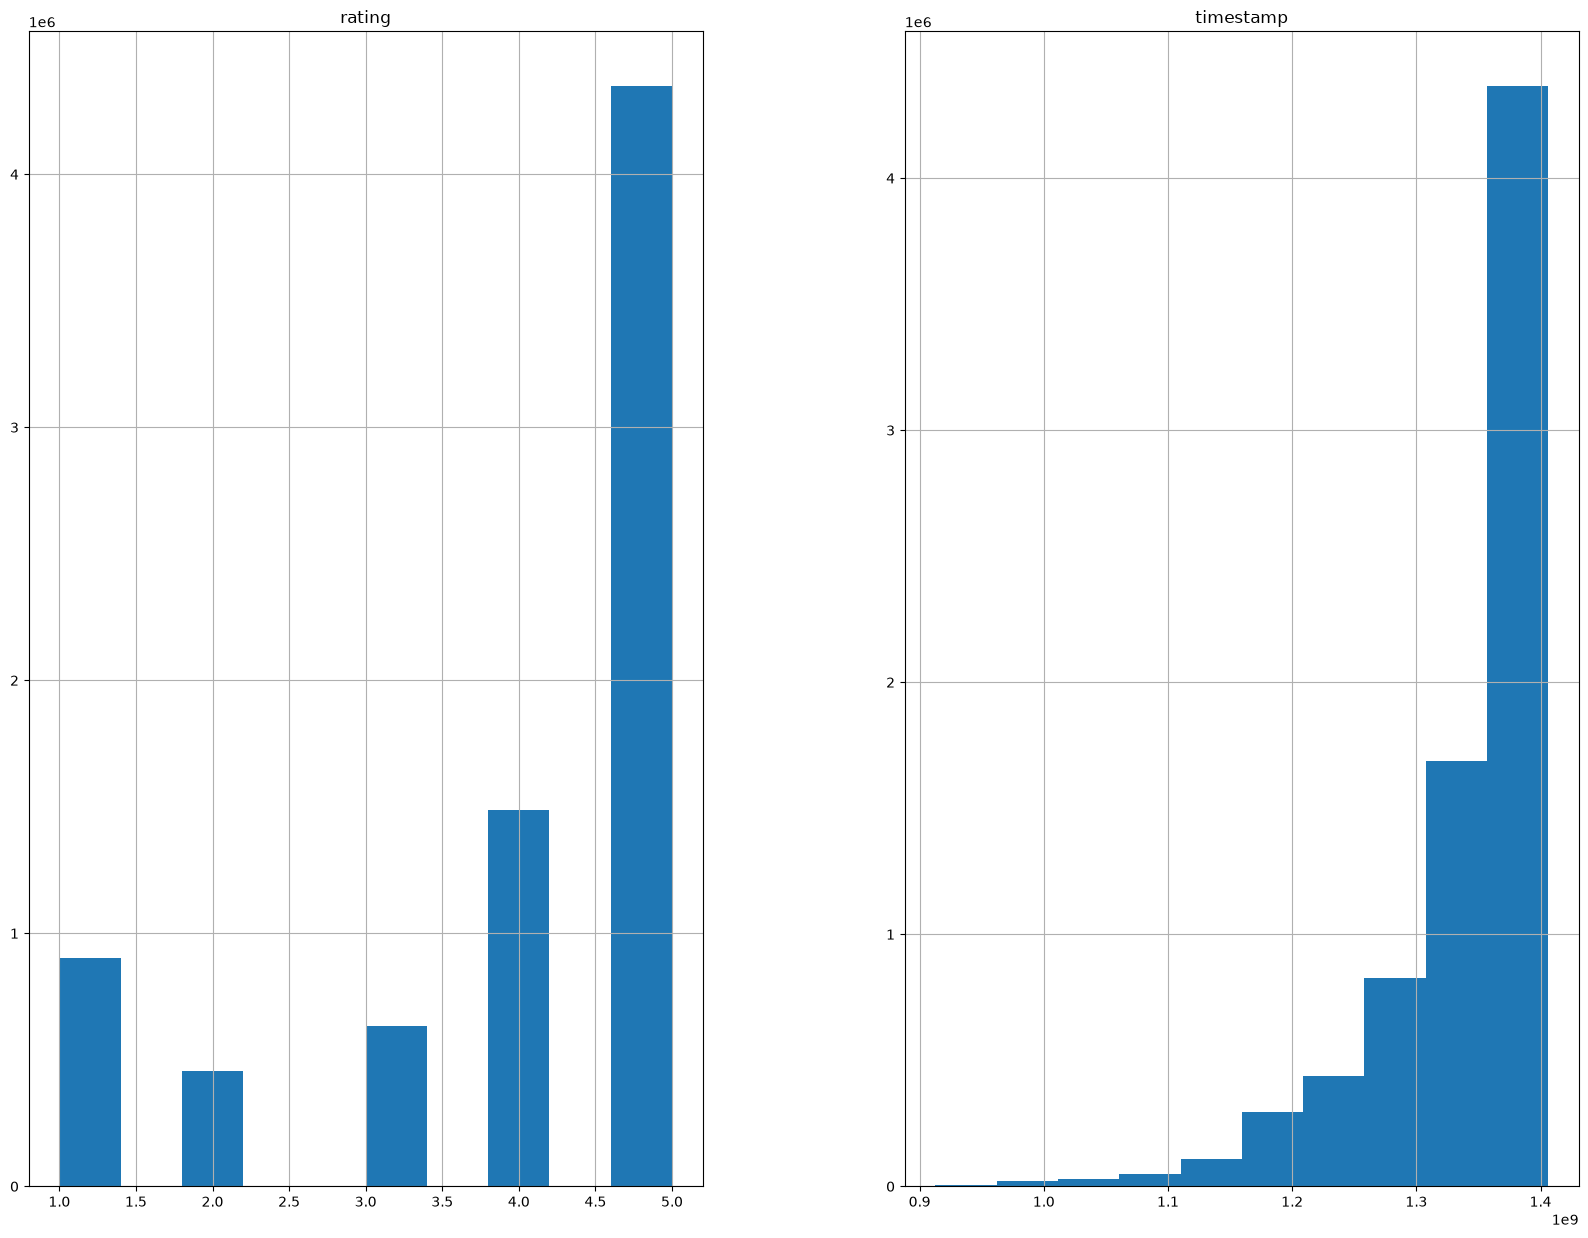

In [7]:
dataset.hist(figsize=(20, 15))
plt.show()

#### Removing the timestamp attribute as it is not required for our analysis

In [8]:
dataset.drop('timestamp',axis=1,inplace=True)

In [9]:
print("Electronic Data Summary")
print("="*100)
print("\nTotal # of Ratings :",dataset.shape[0])
print("Total # of Users   :", len(np.unique(dataset.userId)))
print("Total # of Products  :", len(np.unique(dataset.productId)))
print("\n")
print("="*100)

Electronic Data Summary

Total # of Ratings : 7824481
Total # of Users   : 4201696
Total # of Products  : 476001




In [10]:
#You can reduce the size of the dataset to make it easier to work with. For example, you can take a random sample of 10% of the data.
#dataset = dataset.sample(frac=0.1, random_state=42)

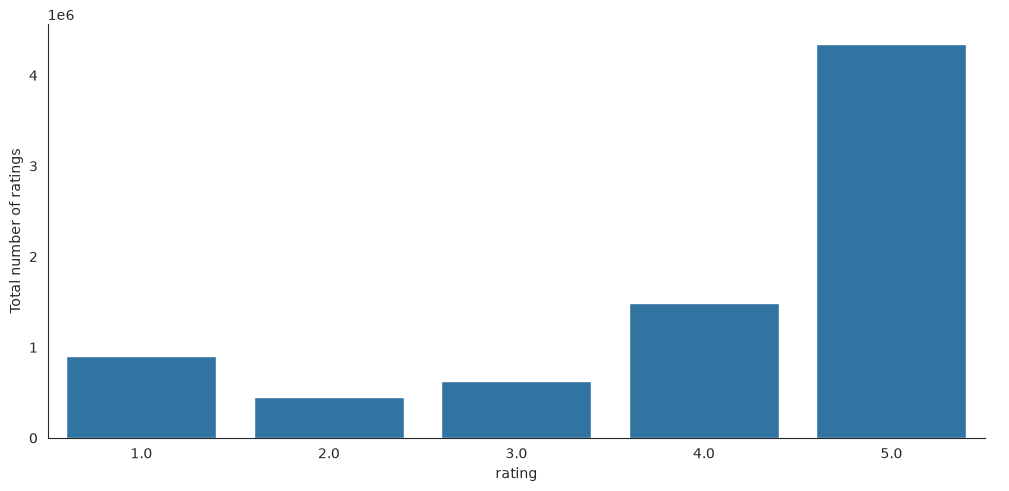

In [11]:
# Check the distribution of the rating
with sns.axes_style('white'):
    g = sns.catplot(x="rating", data=dataset, aspect=2.0, kind='count')
    g.set_ylabels("Total number of ratings")


<Axes: ylabel='rating'>

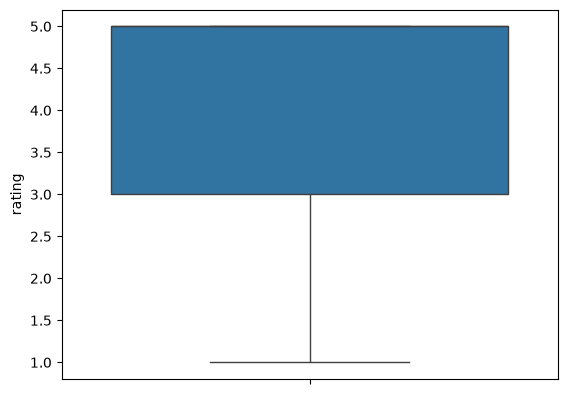

In [12]:
sns.boxplot(y='rating',data=dataset)

### As we can see most of the ratings lie between 3 to 5

### Now lets check no. of products a customer has rated

In [13]:
dataset.drop_duplicates(inplace=True)
most_rated=dataset.groupby('userId').size().sort_values(ascending=False)
print('Users based on ratings: \n',most_rated)

Users based on ratings: 
 userId
A5JLAU2ARJ0BO     520
ADLVFFE4VBT8      501
A3OXHLG6DIBRW8    498
A6FIAB28IS79      431
A680RUE1FDO8B     406
                 ... 
A1V4CBR1EJ58CV      1
AZZYW8JCAHAQY       1
AZZYWDOD33FFE       1
AZZYXVW7BAJVD       1
AIXFJC983FNJI       1
Length: 4201696, dtype: int64


In [14]:
counts=dataset.userId.value_counts()
dataset_final=dataset[dataset.userId.isin(counts[counts>=10].index)]
print('Number of users who have rated 10 or more items =', len(dataset_final))
print('Number of unique users in the final data = ', dataset_final['userId'].nunique())
print('Number of unique products in the final data = ', dataset_final['productId'].nunique())

Number of users who have rated 10 or more items = 1089763
Number of unique users in the final data =  63175
Number of unique products in the final data =  193120


* datasubset_final has the users who have rated 10 or more items. Because users who haven't used/rated much products shouldn't be accounted for.

In [15]:
#statistical analysis of the most rated user data
most_rated.describe().astype(int).T

count    4201696
mean           1
std            2
min            1
25%            1
50%            1
75%            2
max          520
dtype: int64

Text(0.5, 1.0, '# RATINGS per Product')

Text(0.5, 0, 'Product')

Text(0, 0.5, '# ratings per product')

[Text(-25000.0, 0, ''),
 Text(0.0, 0, ''),
 Text(25000.0, 0, ''),
 Text(50000.0, 0, ''),
 Text(75000.0, 0, ''),
 Text(100000.0, 0, ''),
 Text(125000.0, 0, ''),
 Text(150000.0, 0, ''),
 Text(175000.0, 0, ''),
 Text(200000.0, 0, ''),
 Text(225000.0, 0, '')]

<function matplotlib.pyplot.show(close=None, block=None)>

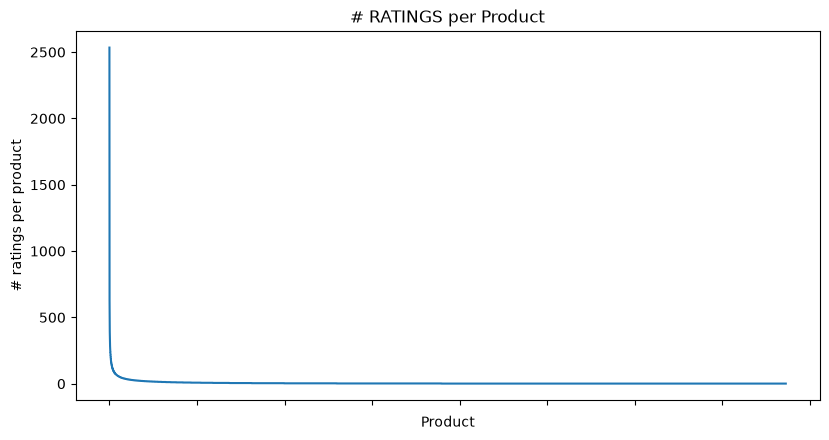

In [16]:
#Products also have skewed ratings with majority of the products having very few ratings
no_of_ratings_per_product = dataset_final.groupby(by='productId')['rating'].count().sort_values(ascending=False)

fig = plt.figure(figsize=plt.figaspect(.5))
ax = plt.gca()
plt.plot(no_of_ratings_per_product.values)
plt.title('# RATINGS per Product')
plt.xlabel('Product')
plt.ylabel('# ratings per product')
ax.set_xticklabels([])

plt.show

In [17]:
ratings_mean_count = pd.DataFrame(dataset_final.groupby('productId')['rating'].mean())
ratings_mean_count['rating_counts'] = pd.DataFrame(dataset_final.groupby('productId')['rating'].count())
ratings_mean_count.head()




,rating,rating_counts
productId,,
0511189877,2.000000,1
0528881469,2.500000,2
0594033926,5.000000,1
0594451647,5.000000,2
0594481813,3.833333,6


In [18]:
#The maximum number of ratings received for a product is 519

ratings_mean_count['rating_counts'].max()

np.int64(2534)

<Figure size 800x600 with 0 Axes>

<Axes: >

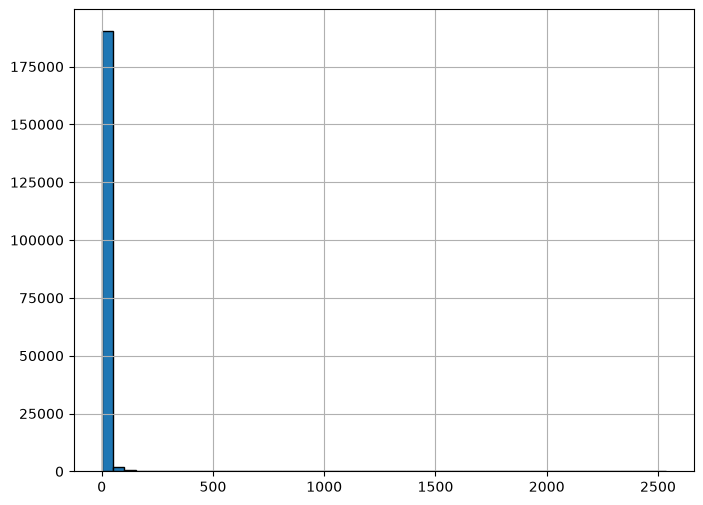

In [19]:
#### Majority of the products have received 1 rating only and it is a right skewed distribution
plt.figure(figsize=(8,6))
plt.rcParams['patch.force_edgecolor'] = True
ratings_mean_count['rating_counts'].hist(bins=50)

<Figure size 800x600 with 0 Axes>

<Axes: >

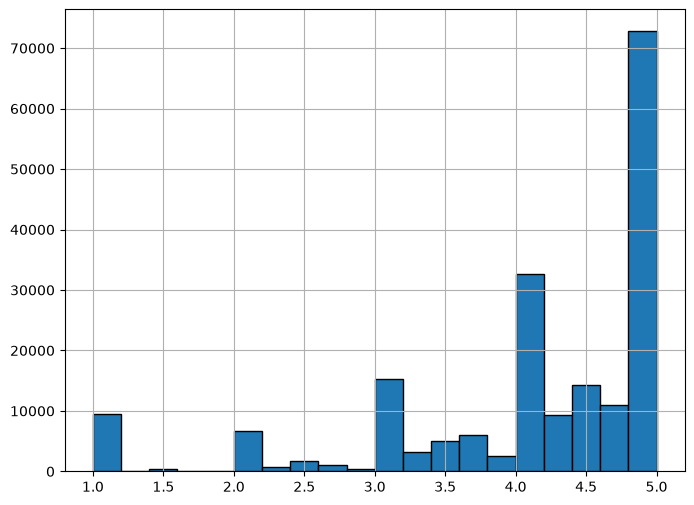

In [20]:
#We see a left skewed distribution for the ratings
#There are clusters at each of the points 1,2,3,4,5 as that is where the means are concentrated
plt.figure(figsize=(8,6))
plt.rcParams['patch.force_edgecolor'] = True
ratings_mean_count['rating'].hist(bins=20)

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

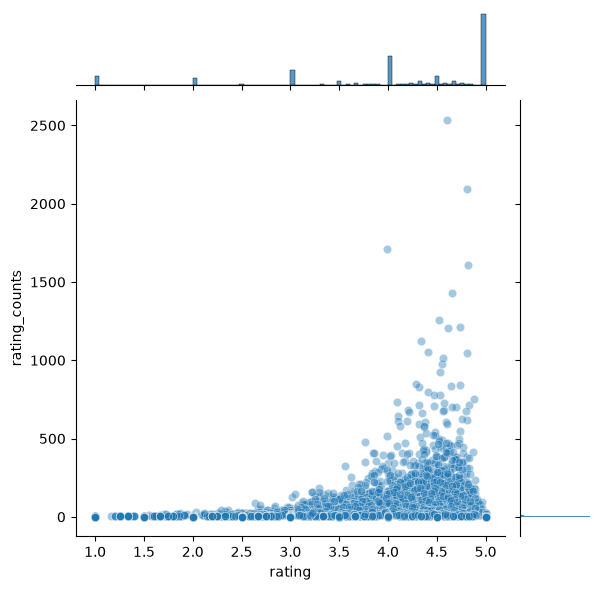

In [21]:
#From the joint plot below it seems that popular products (higher ratings) tend to be rated more frequently, majority have rated products in the higher range
#To make people more engaged (bottom of the chart) we can start by recommending them based on popularity based system and then
#slowly graduate them to collaborative system once we have sufficient number of data points to giver personlized recommendation
plt.figure(figsize=(8,6))
plt.rcParams['patch.force_edgecolor'] = True
sns.jointplot(x='rating', y='rating_counts', data=ratings_mean_count, alpha=0.4)

<Axes: xlabel='productId'>

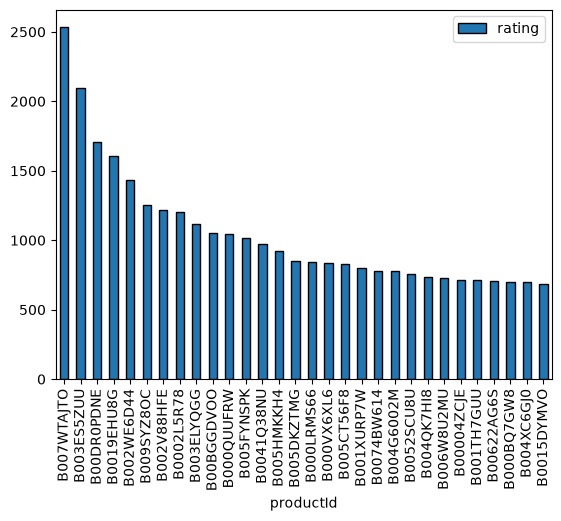

In [22]:
popular_products = pd.DataFrame(dataset_final.groupby('productId')['rating'].count())
most_popular = popular_products.sort_values('rating', ascending=False)
most_popular.head(30).plot(kind = "bar")

In [39]:
no_of_ratings_per_user = dataset_final.groupby(by='userId')['rating'].count().sort_values(ascending=False)

# Section - 3 (Training SVD and SVD++ and Making The Model)

## 1. Training and Testing SVD and SVD++


In [24]:
# Convert the DataFrame into Surprise's dataset format
reader = Reader(rating_scale=(1, 5))
data = Dataset.load_from_df(
    dataset_final[["userId", "productId", "rating"]],
    reader
)

In [25]:
# Creating a train-test split of 70:30 ratio
trainset, testset = surprise_train_test_split(data, test_size=0.3, random_state=42)

In [26]:
# Train SVD
svd = SVD(
    n_factors=50,
    n_epochs=20,
    random_state=42
)
svd.fit(trainset)

# Train SVD++
svdpp = SVDpp(
    n_factors=20,
    n_epochs=20,
    random_state=42
)
svdpp.fit(trainset)

In [27]:
# Evaluate both models
pred_svd = svd.test(testset)
pred_svdpp = svdpp.test(testset)

print("SVD RMSE:")
accuracy.rmse(pred_svd)

print("SVD++ RMSE:")
accuracy.rmse(pred_svdpp)

SVD RMSE:
RMSE: 1.0915


np.float64(1.091540411891732)

SVD++ RMSE:
RMSE: 1.0977


np.float64(1.097666203924543)

#### The SVD model achieved an RMSE of 1.0915, while the SVD++ model achieved an RMSE of 1.0977. SVD showed a marginally better rating-prediction performance on the test dataset. However, the difference was small, and further hyperparameter tuning and ranking-based evaluation are required before concluding that SVD is the better recommendation algorithm.

### 2. Tuning Models for best HyperParameters

In [28]:
#Now, Lets tune the hyperparameters of the SVD model using GridSearchCV to find the best combination of parameters that yield the lowest RMSE.
# Let use the new training and test split for hyperparameter tuning.
ratings_train, ratings_test = sklearn_train_test_split(dataset_final, test_size=0.3, random_state=42)


In [32]:
# Convert the training and test sets into Surprise's dataset format
reader = Reader(rating_scale=(1, 5))
training_ratings = Dataset.load_from_df(
    ratings_train[["userId", "productId", "rating"]],
    reader
)

testing_ratings = Dataset.load_from_df(
    ratings_test[["userId", "productId", "rating"]],
    reader
)

In [33]:
#Choosing the hyperparameter grid for SVD model
svd_param_grid = {
    "n_factors": [20, 50], # Number of latent factors
    "n_epochs": [10, 20], # Number of epochs
    "lr_all": [0.002, 0.005], # Learning rate 
    "reg_all": [0.02, 0.05] # Regularization parameter
}

svd_search = GridSearchCV(
    SVD,
    svd_param_grid,
    measures=["rmse", "mae"],
    cv=3,
    n_jobs=1
)

svd_search.fit(training_ratings)

print("Best SVD RMSE:", svd_search.best_score["rmse"])
print("Best SVD parameters:",
      svd_search.best_params["rmse"])

print("Best SVD MAE:", svd_search.best_score["mae"])

Best SVD RMSE: 1.1012674578342325
Best SVD parameters: {'n_factors': 20, 'n_epochs': 20, 'lr_all': 0.005, 'reg_all': 0.05}
Best SVD MAE: 0.8207215757752975


In [34]:
#Choosing the hyperparameter grid for SVD++ model
svdpp_param_grid = {
    "n_factors": [20, 50], # Number of latent factors
    "n_epochs": [10, 20], # Number of epochs
    "lr_all": [0.002, 0.005], # Learning rate 
    "reg_all": [0.02, 0.05] # Regularization parameter
}

svdpp_search = GridSearchCV(
    SVDpp,
    svdpp_param_grid,
    measures=["rmse", "mae"],
    cv=3,
    n_jobs=1
)

svdpp_search.fit(training_ratings)

print("Best SVD++ RMSE:", svdpp_search.best_score["rmse"])
print("Best SVD++ parameters:",
      svdpp_search.best_params["rmse"])

print("Best SVD++ MAE:", svdpp_search.best_score["mae"])

Best SVD++ RMSE: 1.1028514359096557
Best SVD++ parameters: {'n_factors': 20, 'n_epochs': 20, 'lr_all': 0.005, 'reg_all': 0.05}
Best SVD++ MAE: 0.823273894823827


#### So from our observation we can say SVD performs better as compared to SVD++ so we are going to use SVD for Prediction Model

* Please Note it is recommended to use less number of hyperparameters for Computation otherwise the Computation time would increase significantly with addition of only one parameter 

### Training the Final SVD for Predictions

In [35]:
svd = SVD(
    n_factors=50,
    n_epochs=20,
    random_state=42
)
svd.fit(data.build_full_trainset())

In [ ]:
def recommend_products(user_id,n=10) :
    rated_products = set(dataset_final.loc[dataset_final['userId'] == user_id, 'productId'])
    all_products = dataset_final['productId'].unique()
    unrated_products = [
        product_id for product_id in all_products
        if product_id not in rated_products
    ]

    predictions = []
    for product_id in unrated_products:
        pred = svd.predict(user_id, product_id)
        predictions.append((product_id, pred.est))

    # Sort predictions by estimated rating and return the top n
    predictions.sort(key=lambda x: x[1], reverse=True)
    return predictions[:n]
  


In [50]:

# Select 3 random users from the training data
find_recom = dataset_final['userId'].drop_duplicates().sample(
    n=3, random_state=42
).tolist()

for user_id in find_recom:
    print(f"\nRecommendations for user: {user_id}")
    recommendations = recommend_products(
        user_id=user_id,
        n=5
    )
    for i in range(len(recommendations)):
        print(f"{i+1}. Product ID: {recommendations[i][0]}, Estimated Rating: {recommendations[i][1]:.2f}") 
    



Recommendations for user: A3MEIR72XKQY88
1. Product ID: B0055N2L22, Estimated Rating: 4.81
2. Product ID: B004SCSV2U, Estimated Rating: 4.81
3. Product ID: B00009R6WY, Estimated Rating: 4.80
4. Product ID: B00DBL09FG, Estimated Rating: 4.79
5. Product ID: B001KBZ3SC, Estimated Rating: 4.79

Recommendations for user: A23YL61RAXCLH7
1. Product ID: B00125Y0NU, Estimated Rating: 3.96
2. Product ID: B00108UNEY, Estimated Rating: 3.93
3. Product ID: B007I5JT4S, Estimated Rating: 3.92
4. Product ID: B000VDCTCI, Estimated Rating: 3.91
5. Product ID: B004W2JKWG, Estimated Rating: 3.91

Recommendations for user: A11INR8WEB20VM
1. Product ID: B002G9OZXG, Estimated Rating: 5.00
2. Product ID: B002WE6D44, Estimated Rating: 5.00
3. Product ID: B005T3GPXE, Estimated Rating: 5.00
4. Product ID: B003ZSHNE0, Estimated Rating: 4.99
5. Product ID: B0018LQVIA, Estimated Rating: 4.98
